# Неделя 14. K-Means, DBSCAN, PCA и t-SNE: структура без готовых ответов

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 108 минут практики (2 × 54 минуты). На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** различать кластер и класс, подобрать K-Means по внутренней метрике, увидеть преимущества DBSCAN на дугах, интерпретировать PCA и осторожно читать t-SNE.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_14_clustering_dimensions'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## 1. Контракт данных и unsupervised split

Wine имеет известные классы, но **не передаём их алгоритму и не используем
для выбора k**. Они понадобятся только для заключительного внешнего аудита.
Выделим случайный holdout без стратификации по скрытому классу. Для K-Means/PCA
можем обучить преобразование на train и применить его к новым строкам.


,count,mean,std,min,25%,50%,75%,max
alcohol,133.0,12.97,0.83,11.03,12.29,12.99,13.69,14.83
malic_acid,133.0,2.39,1.10,0.89,1.64,1.90,3.17,5.80
ash,133.0,2.36,0.28,1.36,2.21,2.36,2.54,3.23
alcalinity_of_ash,133.0,19.43,3.47,10.60,17.20,19.40,21.50,30.00
magnesium,133.0,100.76,15.00,70.00,88.00,98.00,108.00,162.00
total_phenols,133.0,2.28,0.65,0.98,1.70,2.23,2.80,3.88
flavanoids,133.0,2.02,1.01,0.34,1.20,2.14,2.88,5.08
nonflavanoid_phenols,133.0,0.36,0.13,0.13,0.26,0.34,0.45,0.66
proanthocyanins,133.0,1.61,0.58,0.42,1.25,1.56,1.96,3.58
color_intensity,133.0,5.02,2.20,1.74,3.25,4.80,6.13,10.80


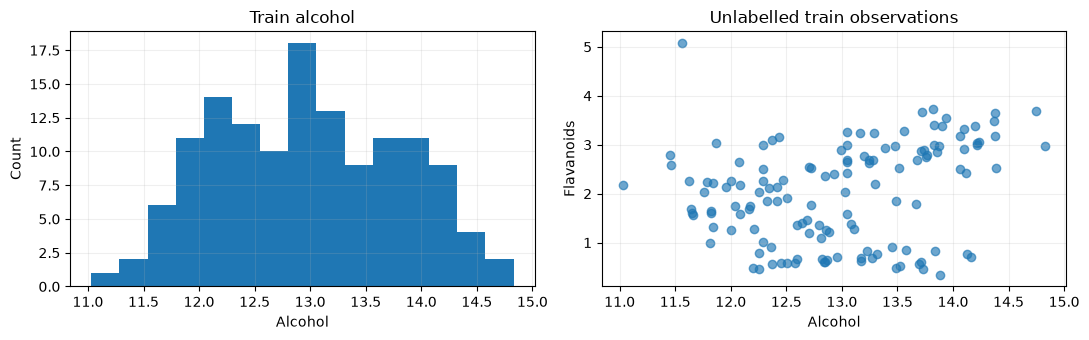

In [2]:
df = pd.read_csv(DATA / "wine.csv").set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
X = df.drop(columns="target")
train_ids, test_ids = train_test_split(df.index, test_size=0.25, random_state=SEED)
X_train, X_test = X.loc[train_ids], X.loc[test_ids]
assert set(train_ids).isdisjoint(test_ids)
display(X_train.describe().T.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
X_train.alcohol.hist(ax=axes[0], bins=15); axes[0].set(title="Train alcohol", xlabel="Alcohol", ylabel="Count")
axes[1].scatter(X_train.alcohol, X_train.flavanoids, alpha=0.65)
axes[1].set(title="Unlabelled train observations", xlabel="Alcohol", ylabel="Flavanoids")
plt.tight_layout(); plt.show()


## 2. K-Means: цель и один ручной шаг

$$J=\sum_i\|x_i-\mu_{c_i}\|^2.$$
Чередуем назначение ближайшего центра и пересчёт центра как среднего кластера.
Фиксируем центры из train, делаем один шаг и проверяем, что objective не вырос
при неизменных назначениях. Стандартизация предотвращает доминирование крупных шкал.


In [3]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)
centers_before = Z_train[[0, 30, 60]].copy()
assignments = ((Z_train[:, None, :] - centers_before[None, :, :])**2).sum(axis=2).argmin(axis=1)
assert set(assignments) == {0, 1, 2}
centers_after = np.vstack([Z_train[assignments == k].mean(axis=0) for k in range(3)])
old_objective = np.sum((Z_train - centers_before[assignments])**2)
new_objective = np.sum((Z_train - centers_after[assignments])**2)
assert new_objective <= old_objective + 1e-9
print({"objective_before": old_objective, "objective_after_center_update": new_objective})


{'objective_before': np.float64(1898.6242918253338), 'objective_after_center_update': np.float64(1153.7519475613667)}


## 3. Внутренний выбор k

Silhouette: $s=(b-a)/\max(a,b)$, где $a$ — среднее расстояние до своего
кластера, $b$ — минимальное среднее расстояние до другого. Больше — компактнее
и лучше разделены найденные группы. Это не доказательство полезных бизнес-сегментов
и не способ гарантированно восстановить неизвестные реальные классы.


In [4]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
candidates, results = {}, []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=15, random_state=SEED).fit(Z_train)
    candidates[k] = model
    results.append({"k": k, "inertia": model.inertia_,
                    "train_silhouette": silhouette_score(Z_train, model.labels_)})
selection = pd.DataFrame(results)
chosen_k = int(selection.sort_values("train_silhouette", ascending=False).iloc[0]["k"])
kmeans = candidates[chosen_k]
display(selection.round(3)); print("Зафиксировано k:", chosen_k)


,k,inertia,train_silhouette
0,2,1232.839,0.261
1,3,950.650,0.285
2,4,862.717,0.265
3,5,813.415,0.229
4,6,749.908,0.241


Зафиксировано k: 3


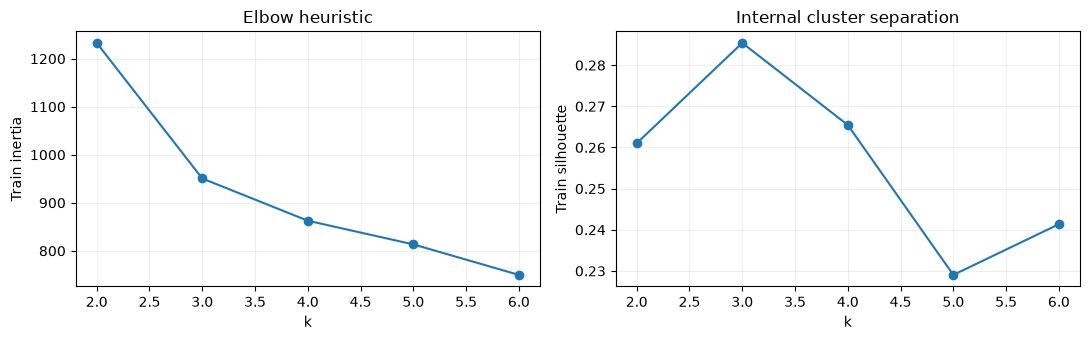

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(selection.k, selection.inertia, "o-"); axes[0].set(xlabel="k", ylabel="Train inertia", title="Elbow heuristic")
axes[1].plot(selection.k, selection.train_silhouette, "o-")
axes[1].set(xlabel="k", ylabel="Train silhouette", title="Internal cluster separation")
plt.tight_layout(); plt.show()


## 4. PCA: линейная проекция с максимальной дисперсией

После центрирования $Z=USV^T$. Главные направления — строки $V^T$;
проекция на первые $q$ компонент: $T=ZV_q$.
`explained_variance_ratio_` описывает долю дисперсии **train**, а не точность
классификатора. Знак компоненты может измениться без изменения смысла геометрии.


Explained variance ratios: [0.3639525  0.18617733]
Доля дисперсии двух компонент: 0.5501298349276386


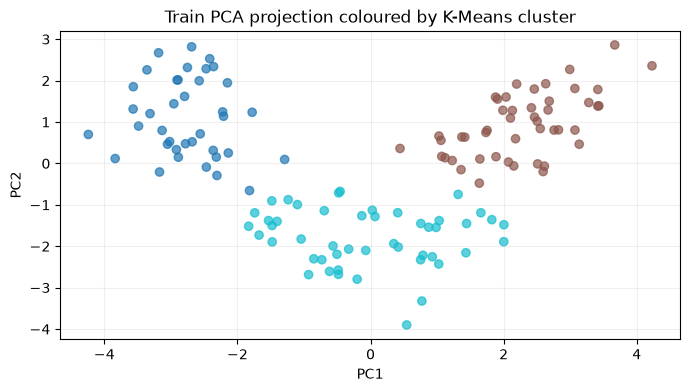

In [6]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, svd_solver="full").fit(Z_train)
projected_train = pca.transform(Z_train)
projected_test = pca.transform(scaler.transform(X_test))
assert projected_train.shape == (len(X_train), 2)
assert np.allclose(pca.components_ @ pca.components_.T, np.eye(2), atol=1e-10)
print("Explained variance ratios:", pca.explained_variance_ratio_)
print("Доля дисперсии двух компонент:", pca.explained_variance_ratio_.sum())
plt.scatter(projected_train[:, 0], projected_train[:, 1], c=kmeans.labels_, cmap="tab10", alpha=0.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Train PCA projection coloured by K-Means cluster")
plt.show()


## 5. Вклад признаков и ошибка восстановления

Нагрузки помогают понять линейное направление. Они не являются причинными
эффектами и не равны feature importance supervised-модели. Восстановление
через две компоненты неизбежно теряет часть информации.


,PC1,PC2
alcohol,0.145,0.491
malic_acid,-0.249,0.214
ash,0.001,0.264
alcalinity_of_ash,-0.233,-0.092
magnesium,0.152,0.263
total_phenols,0.392,0.064
flavanoids,0.417,0.004
nonflavanoid_phenols,-0.286,0.053
proanthocyanins,0.325,0.025
color_intensity,-0.112,0.548


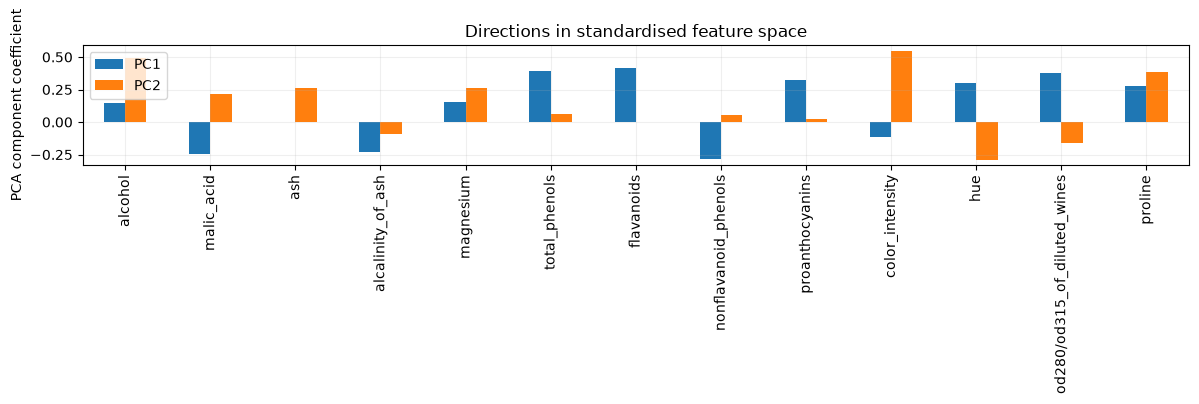

Train reconstruction MSE per coordinate: 0.4498701650723614


In [7]:
loadings = pd.DataFrame(pca.components_.T, index=X_train.columns, columns=["PC1", "PC2"])
display(loadings.round(3))
restored = pca.inverse_transform(projected_train)
reconstruction_mse = np.mean((Z_train-restored)**2)
assert reconstruction_mse >= 0 and np.isfinite(reconstruction_mse)
loadings.plot.bar(figsize=(12, 4)); plt.ylabel("PCA component coefficient")
plt.title("Directions in standardised feature space"); plt.tight_layout(); plt.show()
print("Train reconstruction MSE per coordinate:", reconstruction_mse)


## 6. Проверка на новых строках и внешний аудит классов

K-Means имеет `predict`, PCA — `transform`: используем **те же** train scaler,
центры и компоненты. Теперь впервые раскрываем исходные классы для ARI и таблицы
сопряжённости. Номер кластера произволен: cluster 0 не означает class 0.
После аудита k не меняем.


In [8]:
Z_test = scaler.transform(X_test)
test_clusters = kmeans.predict(Z_test)
cluster_count = len(np.unique(test_clusters))
test_silhouette = silhouette_score(Z_test, test_clusters) if 1 < cluster_count < len(X_test) else np.nan
print("Holdout silhouette:", test_silhouette)
print("External ARI:", adjusted_rand_score(df.loc[test_ids, "target"], test_clusters))
display(pd.crosstab(df.loc[test_ids, "target"], test_clusters, rownames=["true cultivar"], colnames=["cluster"]))
assert len(test_clusters) == len(X_test)


Holdout silhouette: 0.2917713266313355
External ARI: 0.9332105020727776


cluster,0,1,2
true cultivar,,,
0,0,15,0
1,1,0,17
2,12,0,0


## 7. DBSCAN и некруглые группы

На синтетических дугах сравним геометрию K-Means и DBSCAN. `eps` задаёт радиус,
`min_samples` — минимальную плотность. Метка `-1` обозначает шум.
Это **трансдуктивное исследование всего набора**, а не test-оценка новых объектов:
sklearn DBSCAN не имеет стандартного `predict` для новых точек.


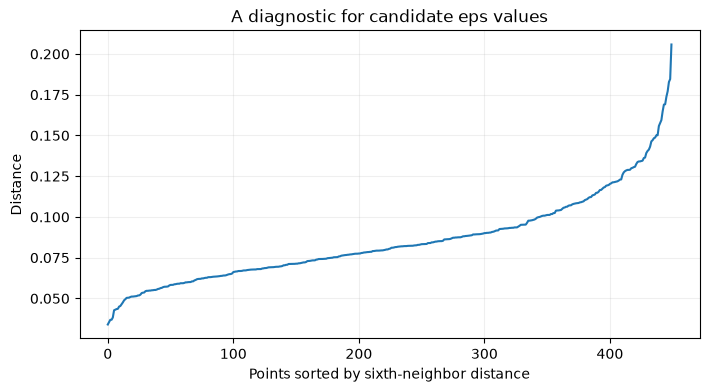

In [9]:
moons = pd.read_csv(DATA / "moons_synthetic.csv")
points = moons[["x1", "x2"]].to_numpy()
from sklearn.neighbors import NearestNeighbors
nearest = NearestNeighbors(n_neighbors=6).fit(points)
neighbor_distances, _ = nearest.kneighbors(points)
plt.plot(np.sort(neighbor_distances[:, -1]))
plt.xlabel("Points sorted by sixth-neighbor distance"); plt.ylabel("Distance")
plt.title("A diagnostic for candidate eps values"); plt.show()


In [10]:
db_rows = []
for eps in [0.10, 0.16, 0.22, 0.32]:
    labels = DBSCAN(eps=eps, min_samples=6).fit_predict(points)
    non_noise = labels != -1
    n_clusters = len(set(labels) - {-1})
    # Silhouette определён только для 2..n-1 групп и не учитывает исключённый шум.
    score = silhouette_score(points[non_noise], labels[non_noise]) if 1 < n_clusters < non_noise.sum() else np.nan
    db_rows.append({"eps": eps, "clusters": n_clusters, "noise_fraction": 1-non_noise.mean(),
                    "silhouette_excluding_noise": score})
display(pd.DataFrame(db_rows).round(3))


,eps,clusters,noise_fraction,silhouette_excluding_noise
0,0.10,5,0.069,0.468
1,0.16,2,0.000,0.326
2,0.22,2,0.000,0.326
3,0.32,1,0.000,NaN


## 8. Геометрия и метрика могут расходиться

Зафиксируем `eps=0.16` как объяснительный вариант. На дугах силуэт может предпочесть
компактные группы K-Means, хотя DBSCAN лучше повторяет форму генератора.
Поэтому нельзя выбирать алгоритм по единственному числу без цели исследования.


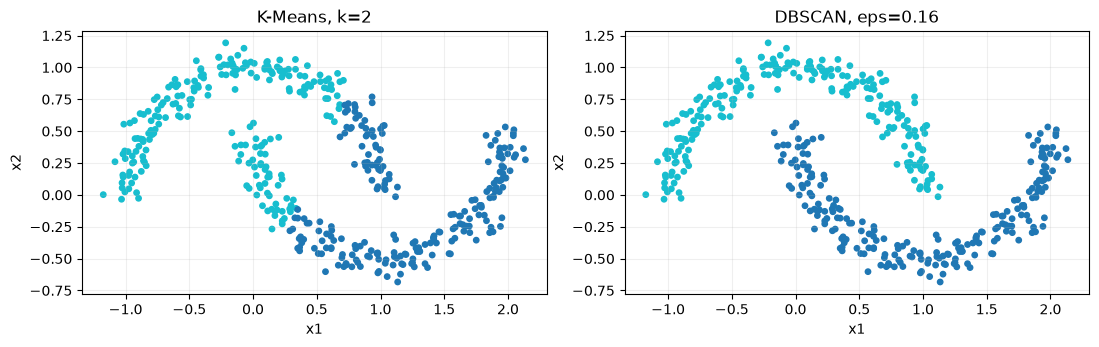

ARI after revealing synthetic generator labels: {'K-Means': 0.2416888888888889, 'DBSCAN': 1.0}


In [11]:
km_moons = KMeans(n_clusters=2, n_init=15, random_state=SEED).fit_predict(points)
db_moons = DBSCAN(eps=0.16, min_samples=6).fit_predict(points)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, labels, name in zip(axes, [km_moons, db_moons], ["K-Means, k=2", "DBSCAN, eps=0.16"]):
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="tab10", s=15)
    ax.set(title=name, xlabel="x1", ylabel="x2", aspect="equal")
plt.tight_layout(); plt.show()
print("ARI after revealing synthetic generator labels:",
      {"K-Means": adjusted_rand_score(moons.target, km_moons),
       "DBSCAN": adjusted_rand_score(moons.target, db_moons)})


## 9. t-SNE: локальные соседства, не карта физических расстояний

Делаем **две визуализации train** при разных perplexity. Не обучаем на train+test,
не выбираем модель по красоте картинки. t-SNE не сохраняет глобальные расстояния
и размеры групп, а стандартный sklearn TSNE не имеет `transform` для новых строк.
Random seed, perplexity и начальная проекция влияют на результат.


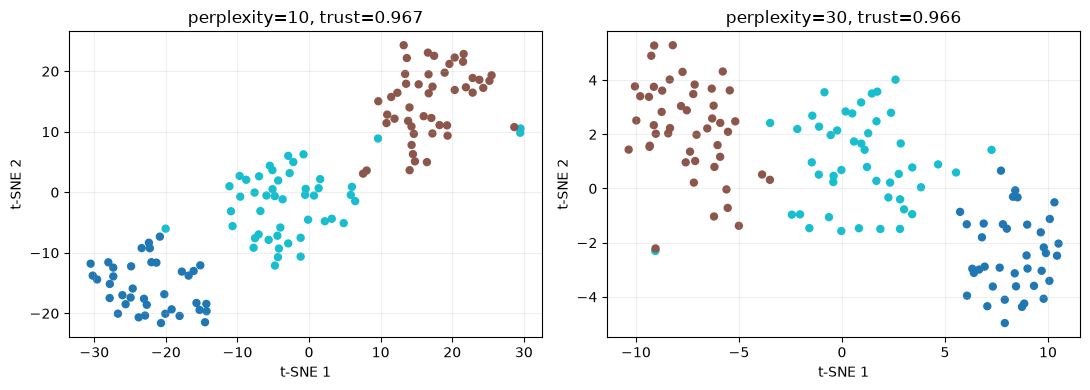

In [12]:
from sklearn.manifold import TSNE, trustworthiness
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, perplexity in zip(axes, [10, 30]):
    embedding = TSNE(n_components=2, perplexity=perplexity, init="pca",
                     learning_rate="auto", max_iter=600, random_state=SEED).fit_transform(Z_train)
    assert embedding.shape == (len(Z_train), 2) and np.isfinite(embedding).all()
    local_score = trustworthiness(Z_train, embedding, n_neighbors=5)
    ax.scatter(embedding[:, 0], embedding[:, 1], c=kmeans.labels_, cmap="tab10", s=25)
    ax.set(title=f"perplexity={perplexity}, trust={local_score:.3f}", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout(); plt.show()


## Выводы, которые можно защищать

Напишите отдельно: что обнаружено алгоритмом, как это измерено и что остаётся
неизвестным. Кластер не обязан совпадать с классом. Высокая доля дисперсии PCA
не гарантирует полезность для prediction. Красивые острова t-SNE не доказывают,
что исходные данные имеют именно столько изолированных групп.

Источники: [Stanford CS229 notes](https://cs229.stanford.edu/main_notes.pdf),
[scikit-learn clustering](https://scikit-learn.org/stable/modules/clustering.html),
[PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca),
[van der Maaten & Hinton, t-SNE](https://jmlr.org/papers/v9/vandermaaten08a.html),
[TSNE API](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html).
